# Sri Lanka Gold Rate forecasting by Forex rates using ML approaches

### Index Number 224112A
### Assignment 1 for Machine Learning and Pattern Recognition

## Data Sources
### Central Bank of Sri Lanka
### Links
* https://www.cbsl.gov.lk/en/rates-and-indicators/exchange-rates#:~:text=Daily%20Buying%20and%20Selling%20Exchange%20Rate%202005%2D%20Latest%20(Telegraphic%20Transfers)
* https://www.cbsl.gov.lk/en/rates-and-indicators/exchange-rates/daily-gold-rates




In [1]:
# Install Python packages
%pip install -q pandas numpy openpyxl matplotlib scikit-learn xgboost lightgbm catboost statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the installed libraries
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Data Pre-processing

CBSL provides an excel file for the forex range and a CSV for gold prices, I made them both to a CSV.

In [3]:
RAW_XLSX = "IF_Buying_Selling_Exchange_Rates.xlsx"
CLEAN_FX_CSV = "cbsl_exchange_rates_clean.csv"

# Inspect the excel file
raw = pd.read_excel(RAW_XLSX, sheet_name="2005-2026", header=None)
print(f"Raw workbook shape: {raw.shape}")
print(f"Non-null cells in Col 0 (A): {raw.iloc[:, 0].notnull().sum()}")

print("\n--- First 10 rows (first 8 cols) ---")
display(raw.iloc[:10, :8])

print("\n--- Last 5 rows (first 6 cols) ---")
display(raw.iloc[-5:, :6])

Raw workbook shape: (5798, 20)
Non-null cells in Col 0 (A): 0

--- First 10 rows (first 8 cols) ---


,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Buying & Selling Exchange Rates of Commercial ...,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,United States,NaN,Great Britain,NaN,European Union,NaN
4,NaN,NaN,Buying,Selling,Buying,Selling,Buying,Selling
5,NaN,NaN,USD,USD,GBP,GBP,EUR,EUR
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,2005-01-03 00:00:00,103.52,104.57,196.92,199.69,138.77,141.08
8,NaN,2005-01-04 00:00:00,102.64,103.94,195.22,198.53,137.77,140.46
9,NaN,2005-01-05 00:00:00,100.12,101.76,188.23,191.99,132.47,135.33



--- Last 5 rows (first 6 cols) ---


,0,1,2,3,4,5
5793,NaN,2026-10-30 00:00:00,328.0447,337.1431,438.2714,452.8744
5794,NaN,Average October,326.972923,335.986514,433.422932,447.856723
5795,NaN,NaN,NaN,NaN,NaN,NaN
5796,NaN,(a) The average buying and selling exchange ra...,NaN,NaN,NaN,NaN
5797,NaN,,NaN,NaN,NaN,NaN


Some merged headers and blanks were noted, and there is a monthly Average and some footer rows

In [4]:
# 2. Extract raw table from the Excel sheet (rows 8+, cols B..T) to run quality checks BEFORE cleaning
currencies = ["USD", "GBP", "EUR", "CHF", "CAD", "AUD", "SGD", "JPY", "CNY"]
fx_cols = ["Date"] + [f"{cur}_{side}" for cur in currencies for side in ("Buy", "Sell")]

df_audit = raw.iloc[7:, 1:20].copy()
df_audit.columns = fx_cols

In [5]:
# Check 1: Non-date rows interleaved inside the table
is_dt = df_audit["Date"].apply(lambda x: isinstance(x, (datetime.datetime, pd.Timestamp)))
non_dt_samples = df_audit.loc[~is_dt, "Date"].dropna().unique()[:8]
print(f"[Check 1] Non-date rows found: {(~is_dt).sum()} | Examples: {list(non_dt_samples)}")

# Keep valid datetime rows for value-level checks
df_raw_daily = df_audit[is_dt].copy()
df_raw_daily["Date"] = pd.to_datetime(df_raw_daily["Date"])
for col in fx_cols[1:]:
    df_raw_daily[col] = pd.to_numeric(df_raw_daily[col], errors="coerce")


[Check 1] Non-date rows found: 526 | Examples: ['Average January', 'Average February', 'Average March', 'Average April', 'Average May', 'Average June', 'Average July', 'Average August']


In [6]:

# Check 2: Chronological integrity in sheet order (backwards jumps, weekends, duplicates)
df_raw_daily = df_raw_daily.reset_index(drop=True)  # keep original CBSL sheet order

goes_back = df_raw_daily["Date"].diff().dt.days < 0
weekend   = df_raw_daily["Date"].dt.day_of_week >= 5
dup_mask  = df_raw_daily["Date"].duplicated(keep=False)

print(f"\n[Check 2] Dates going backwards in sheet order: {goes_back.sum()} | Weekend-dated rows: {weekend.sum()} | Duplicate-date rows: {dup_mask.sum()}")
suspect = df_raw_daily.loc[goes_back, ["Date", "USD_Sell", "GBP_Buy", "CAD_Buy", "CNY_Buy"]].copy()
suspect["Prev_Row_Date"] = df_raw_daily["Date"].shift(1)[goes_back]
suspect["Next_Row_Date"] = df_raw_daily["Date"].shift(-1)[goes_back]
display(suspect)




[Check 2] Dates going backwards in sheet order: 3 | Weekend-dated rows: 1 | Duplicate-date rows: 4


,Date,USD_Sell,GBP_Buy,CAD_Buy,CNY_Buy,Prev_Row_Date,Next_Row_Date
2838,2015-10-06,148.330,183.3700,108.9200,NaN,2016-10-05,2016-10-07
2901,2016-01-09,151.780,180.8400,111.1800,21.1300,2017-01-06,2017-01-10
3558,2018-10-01,183.755,220.0924,135.0525,24.8994,2019-09-30,2019-10-02


### Diagnosis: each misdated row carries the PREVIOUS year's stamp -> restore the year when it fits between its sheet neighbours

In [7]:

df_dates_fixed = df_raw_daily.copy()
date_fix_log = []
for i in df_dates_fixed.index[goes_back]:
    cand = df_dates_fixed.at[i, "Date"] + pd.DateOffset(years=1)
    prev_d = df_dates_fixed.at[i - 1, "Date"]
    next_d = df_dates_fixed.at[i + 1, "Date"] if i + 1 in df_dates_fixed.index else pd.Timestamp.max
    if prev_d < cand < next_d:
        date_fix_log.append((df_dates_fixed.at[i, "Date"].date(), cand.date()))
        df_dates_fixed.at[i, "Date"] = cand
print(f"Corrected {len(date_fix_log)} year-stamp typos: {date_fix_log}")
print("\n")
print(f"After correction -> duplicates: {df_dates_fixed['Date'].duplicated().sum()} | weekend rows: {(df_dates_fixed['Date'].dt.day_of_week >= 5).sum()} | monotonic: {df_dates_fixed['Date'].is_monotonic_increasing}")

Corrected 3 year-stamp typos: [(datetime.date(2015, 10, 6), datetime.date(2016, 10, 6)), (datetime.date(2016, 1, 9), datetime.date(2017, 1, 9)), (datetime.date(2018, 10, 1), datetime.date(2019, 10, 1))]


After correction -> duplicates: 0 | weekend rows: 0 | monotonic: True


### Check 3: Domain rule violations (Rate <= 0 or Selling < Buying)
Checking for basic financial sense in the data.

In [8]:
domain_issues = []
for cur in currencies:
    b_col, s_col = f"{cur}_Buy", f"{cur}_Sell"
    bad = df_raw_daily[(df_raw_daily[b_col] <= 0) | (df_raw_daily[s_col] <= 0) | (df_raw_daily[s_col] < df_raw_daily[b_col])]
    for _, r in bad.iterrows():
        domain_issues.append({"Date": r["Date"].date(), "Currency": cur, "Buy": r[b_col], "Sell": r[s_col]})
df_domain_issues = pd.DataFrame(domain_issues)
print(f"\n[Check 3] Financial domain violations (<=0 or Sell < Buy): {len(df_domain_issues)}")
display(df_domain_issues)


[Check 3] Financial domain violations (<=0 or Sell < Buy): 13


,Date,Currency,Buy,Sell
0,2005-07-05,USD,99.6800,98.7800
1,2006-05-15,EUR,137.7200,134.1700
2,2006-11-29,EUR,147.0700,144.1600
3,2007-03-30,EUR,166.2600,147.2200
4,2021-01-08,EUR,237.8470,234.2258
5,2007-08-20,CHF,91.8200,84.1200
6,2006-06-23,AUD,78.1800,76.9900
7,2006-09-08,AUD,76.5600,75.8700
8,2007-07-30,AUD,96.9600,96.4200
9,2006-08-29,JPY,0.8729,0.0913


In [9]:
# Audit Check 4: Isolated 1-day >15% spikes (revert immediately the next trading day)
df_sorted = df_dates_fixed.sort_values("Date").reset_index(drop=True)
spike_issues = []
for col in fx_cols[1:]:
    prev_v, next_v = df_sorted[col].shift(1), df_sorted[col].shift(-1)
    mask = ((df_sorted[col] - prev_v).abs() / prev_v > 0.15) & ((df_sorted[col] - next_v).abs() / next_v > 0.15)
    for idx in df_sorted[mask].index:
        spike_issues.append({
            "Date": df_sorted.loc[idx, "Date"].date(),
            "Column": col,
            "Prev_Day": round(prev_v.loc[idx], 4),
            "Observed": round(df_sorted.loc[idx, col], 4),
            "Next_Day": round(next_v.loc[idx], 4),
        })
print(f"\n[Check 4] Isolated 1-day >15% typo spikes found: {len(spike_issues)}")
display(pd.DataFrame(spike_issues))


[Check 4] Isolated 1-day >15% typo spikes found: 11


,Date,Column,Prev_Day,Observed,Next_Day
0,2007-03-30,EUR_Buy,144.0200,166.2600,143.7800
1,2020-04-20,EUR_Buy,203.6190,168.8441,204.9465
2,2008-08-14,CHF_Sell,100.3800,161.5800,99.0600
3,2015-10-28,CAD_Sell,109.4200,180.4700,109.0400
4,2005-12-30,AUD_Buy,73.5800,0.8580,73.9700
5,2005-12-30,AUD_Sell,75.2900,0.8764,75.9100
6,2006-08-29,JPY_Sell,0.8919,0.0913,0.8902
7,2007-05-25,JPY_Sell,0.9217,0.0000,0.9211
8,2007-06-18,JPY_Sell,0.9123,0.0000,0.9074
9,2007-12-05,JPY_Sell,1.0110,0.0000,0.9882


### Plots for discovering CBSL typing mistakes

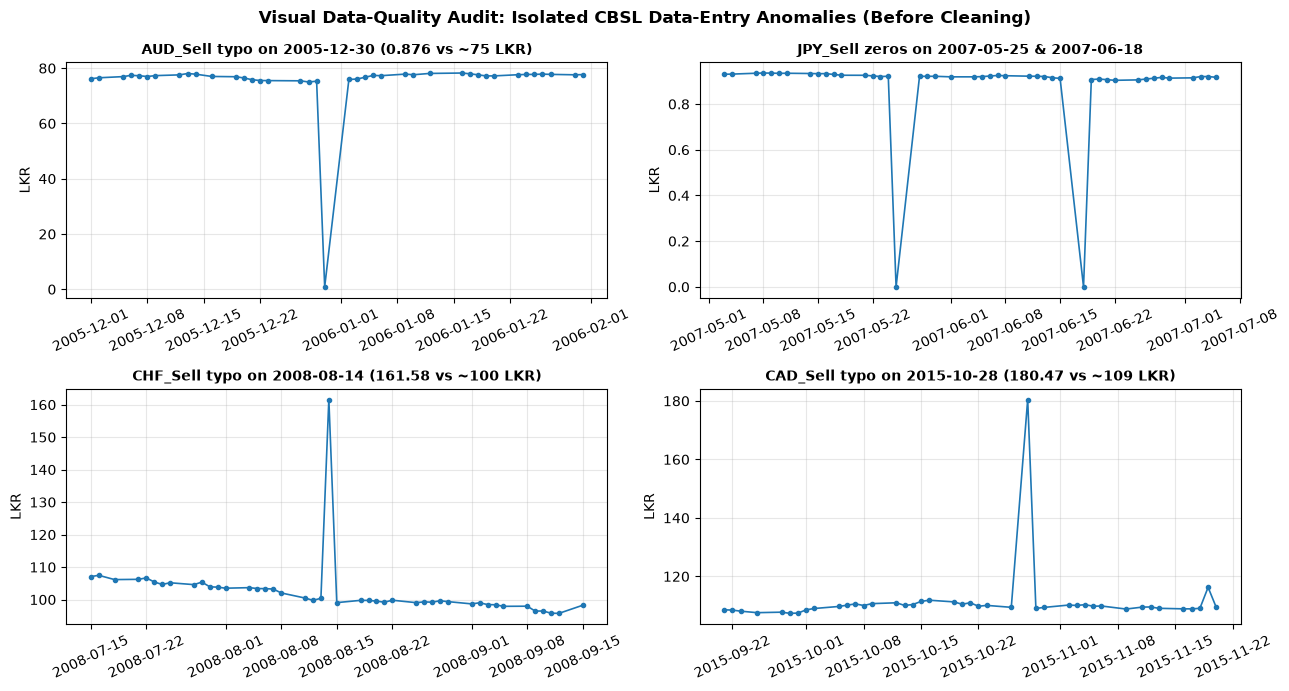

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
cases = [
    ("AUD_Sell", "2005-12-01", "2006-01-31", "AUD_Sell typo on 2005-12-30 (0.876 vs ~75 LKR)"),
    ("JPY_Sell", "2007-05-01", "2007-07-05", "JPY_Sell zeros on 2007-05-25 & 2007-06-18"),
    ("CHF_Sell", "2008-07-15", "2008-09-15", "CHF_Sell typo on 2008-08-14 (161.58 vs ~100 LKR)"),
    ("CAD_Sell", "2015-09-20", "2015-11-20", "CAD_Sell typo on 2015-10-28 (180.47 vs ~109 LKR)"),
]

for ax, (col, start, end, title) in zip(axes.flat, cases):
    win = df_sorted[(df_sorted["Date"] >= start) & (df_sorted["Date"] <= end)]
    ax.plot(win["Date"], win[col], marker="o", markersize=3, linewidth=1.2, color="#1f77b4")
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_ylabel("LKR")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("Visual Data-Quality Audit: Isolated CBSL Data-Entry Anomalies (Before Cleaning)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

Cleaning  and Export a Cleaned CSV (`cbsl_exchange_rates_clean.csv`)

Based  on the findings above, applied a cleaning pipe
1. Strip the `7` merged header rows, empty column `A`, and `526` interleaved non-date rows.
2. Restore the correct year on the 3 misdated CBSL rows  by replacement.
    (`2015-10-06 -> 2016-10-06`, `2016-01-09 (Sat) -> 2017-01-09`, `2018-10-01 -> 2019-10-01`).
    _This removes both duplicates and the weekend row without discarding any real trading days._
3. Mask the `13` domain-rule violations (`<= 0` or `Selling < Buying`) and isolated 1-day `>15%` typo spikes as `NaN`, then fill only internal gaps via linear interpolation (leaving leading `NaN`s intact for currencies introduced after 2005: `CAD`, `SGD`, `CNY`). Genuine multi-day macro shocks (like the 2022 LKR float) are untouched.


## Exported a flat CSV table to `cbsl_exchange_rates_clean.csv` and verify for any remaining violations.

In [11]:
# Build clean daily exchange rate DataFrame from the date-corrected table
df_fx = df_dates_fixed.sort_values("Date").drop_duplicates(subset=["Date"], keep="first").reset_index(drop=True)

typo_log = []



Basic profitable rule in any trade is Fix <= 0 or Selling < Buying
So, check and correct them.

In [12]:
for cur in currencies:
    b_col, s_col = f"{cur}_Buy", f"{cur}_Sell"
    bad_mask = (df_fx[b_col] <= 0) | (df_fx[s_col] <= 0) | (df_fx[s_col] < df_fx[b_col])
    if bad_mask.any():
        for dt in df_fx.loc[bad_mask, "Date"]:
            typo_log.append((dt.strftime("%Y-%m-%d"), cur, "Zero/Negative or Sell < Buy"))
        df_fx.loc[bad_mask, [b_col, s_col]] = np.nan



### Fix isolated 1-day >15% spikes that revert immediately
These should be random noise due to data entry, by checking the data plots we saw earlier, as a greater than 15% fluctuation is highly unlikely in any sense, and if it returns back the next day, it's probably a data quality problem.

In [13]:
for col in fx_cols[1:]:
    prev_val = df_fx[col].shift(1)
    next_val = df_fx[col].shift(-1)
    isolated_spike = ((df_fx[col] - prev_val).abs() / prev_val > 0.15) & ((df_fx[col] - next_val).abs() / next_val > 0.15)
    if isolated_spike.any():
        for dt in df_fx.loc[isolated_spike, "Date"]:
            typo_log.append((dt.strftime("%Y-%m-%d"), col, "Isolated >15% 1-day spike"))
        df_fx.loc[isolated_spike, col] = np.nan


Interpolate only internal gaps (preserve leading NaNs for post-2005 currencies)

In [14]:

for col in fx_cols[1:]:
    first_valid = df_fx[col].first_valid_index()
    if first_valid is not None:
        df_fx.loc[first_valid:, col] = df_fx.loc[first_valid:, col].interpolate(method="linear")



### Export the cleaned data to a CSV file

In [15]:

df_fx.to_csv(CLEAN_FX_CSV, index=False, date_format="%Y-%m-%d")

# Post-cleaning verification
remaining_sell_lt_buy = sum((df_fx[f"{c}_Sell"] < df_fx[f"{c}_Buy"]).sum() for c in currencies)
print(f"Fixed {len(typo_log)} anomalies | Remaining duplicates: {df_fx['Date'].duplicated().sum()} | Weekend rows: {(df_fx['Date'].dt.day_of_week >= 5).sum()} | Monotonic: {df_fx['Date'].is_monotonic_increasing} | Remaining Sell<Buy: {remaining_sell_lt_buy}")
print(f"Saved clean CSV -> {CLEAN_FX_CSV} ({df_fx.shape[0]} rows x {df_fx.shape[1]} cols)")
print(f"Date range: {df_fx['Date'].min().date()} to {df_fx['Date'].max().date()}")
display(df_fx.head())

Fixed 19 anomalies | Remaining duplicates: 0 | Weekend rows: 0 | Monotonic: True | Remaining Sell<Buy: 0
Saved clean CSV -> cbsl_exchange_rates_clean.csv (5265 rows x 19 cols)
Date range: 2005-01-03 to 2026-10-30


,Date,USD_Buy,USD_Sell,GBP_Buy,GBP_Sell,EUR_Buy,EUR_Sell,CHF_Buy,CHF_Sell,CAD_Buy,CAD_Sell,AUD_Buy,AUD_Sell,SGD_Buy,SGD_Sell,JPY_Buy,JPY_Sell,CNY_Buy,CNY_Sell
0,2005-01-03,103.52,104.57,196.92,199.69,138.77,141.08,89.46,91.46,NaN,NaN,79.87,81.61,NaN,NaN,1.0026,1.02060,NaN,NaN
1,2005-01-04,102.64,103.94,195.22,198.53,137.77,140.46,88.87,91.24,NaN,NaN,79.20,81.22,NaN,NaN,0.9949,1.01670,NaN,NaN
2,2005-01-05,100.12,101.76,188.23,191.99,132.47,135.33,85.17,87.55,NaN,NaN,76.19,78.24,NaN,NaN,0.9554,0.97740,NaN,NaN
3,2005-01-06,98.53,100.33,185.42,189.45,130.35,133.40,83.86,86.40,NaN,NaN,74.98,77.05,NaN,NaN,0.9437,0.96780,NaN,NaN
4,2005-01-07,98.58,100.24,184.49,188.64,129.38,132.71,83.34,86.06,NaN,NaN,74.59,76.93,NaN,NaN,0.9358,0.96117,NaN,NaN


### Visual Verification by Checking the plots
Before (raw) vs. After (cleaned) across the exact same abnormalities.

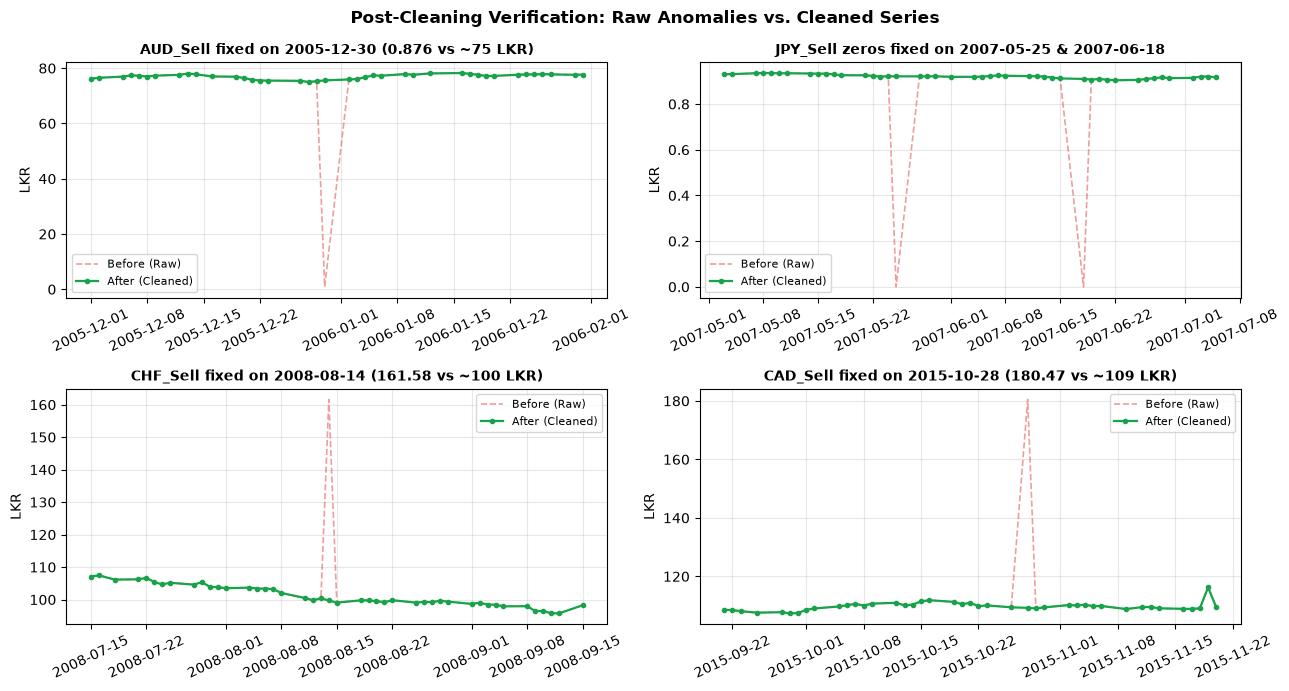

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (col, start, end, title) in zip(axes.flat, cases):
    win_raw = df_sorted[(df_sorted["Date"] >= start) & (df_sorted["Date"] <= end)]
    win_clean = df_fx[(df_fx["Date"] >= start) & (df_fx["Date"] <= end)]
    ax.plot(win_raw["Date"], win_raw[col], linestyle="--", color="#dc2626", alpha=0.45, linewidth=1.2, label="Before (Raw)")
    ax.plot(win_clean["Date"], win_clean[col], marker="o", markersize=3, linewidth=1.6, color="#16a34a", label="After (Cleaned)")
    ax.set_title(title.replace("typo", "fixed").replace("zeros", "zeros fixed"), fontsize=10, fontweight="bold")
    ax.set_ylabel("LKR")
    ax.legend(fontsize=8, loc="best")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("Post-Cleaning Verification: Raw Anomalies vs. Cleaned Series", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## Step 2: Audit Gold Data, Merge with FX Rates, EDA & Strictly Lagged Feature Engineering

Next, audit the gold_rate_data.csv which was downloaded directly from CBSL (CBSL Daily Gold Price in LKR per Troy oz.)
Then merge it with `cbsl_exchange_rates_clean.csv`, and inspect the combined dataset:

Since the Gold data starts in 2010-05-07 using data from there onwards.


Feature Engineering
* **Anti-leakage rule:** Because CBSL derives today's `Gold_LKR(t)` using today's `USD_LKR(t)` spot rate, **all predictive features are strictly lagged (`t-1` or earlier)** so the models only see information genuinely available before day `t`.


For easy understanding...
* * **Sri Lankan local unit:** tracking `Gold_Pawan_LKR = Gold_LKR * (8 / 31.1035)` (1 Sovereign / Pawan = 8 grams of 24K gold) for intuitive local interpretation.

### Load & audit gold_rate_data.csv

In [17]:
df_gold = pd.read_csv("gold_rate_data.csv")
df_gold["Date"] = pd.to_datetime(df_gold["Date"])
df_gold = df_gold.rename(columns={"Exchange Rate": "Gold_LKR"}).sort_values("Date").reset_index(drop=True)

print(f"Gold CSV shape: {df_gold.shape} | Nulls: {df_gold.isnull().sum().to_dict()} | Duplicate dates: {df_gold['Date'].duplicated().sum()}")
print(f"Gold date range: {df_gold['Date'].min().date()} to {df_gold['Date'].max().date()}")

Gold CSV shape: (3537, 3) | Nulls: {'Currency': 0, 'Date': 0, 'Gold_LKR': 0} | Duplicate dates: 0
Gold date range: 2010-05-07 to 2026-11-20


### Check any large single-day Gold jumps (>15%)

In [18]:

gold_jumps = df_gold[df_gold["Gold_LKR"].pct_change().abs() > 0.15]
print(f"Gold single-day jumps > 15%")
display(gold_jumps)

Gold single-day jumps > 15%


,Currency,Date,Gold_LKR
2397,XAU,2022-03-09,470485.3275


Preserved — genuine 2022 LKR float shock, with the country in crisis.

### Inner-merge clean FX + Gold on Date and inspect CNY coverage before dropping
Since CNY only starts in 2017 January, better to keep it out and use the other currencies.

In [19]:

df_fx_clean = pd.read_csv(CLEAN_FX_CSV, parse_dates=["Date"])
cny_start = df_fx_clean.loc[df_fx_clean["CNY_Sell"].first_valid_index(), "Date"].date()
df_merged_check = pd.merge(df_fx_clean[["Date", "CNY_Sell"]], df_gold[["Date"]], on="Date", how="inner")
cny_missing_merged = int(df_merged_check["CNY_Sell"].isnull().sum())
print(f"\nCNY starts on {cny_start} (missing in {cny_missing_merged} merged rows -> dropping CNY_Buy/CNY_Sell for complete 2010–2026 coverage).")




CNY starts on 2017-01-02 (missing in 1149 merged rows -> dropping CNY_Buy/CNY_Sell for complete 2010–2026 coverage).


In [20]:
df_merged = pd.merge(
    df_fx_clean.drop(columns=["CNY_Buy", "CNY_Sell"]),
    df_gold[["Date", "Gold_LKR"]],
    on="Date",
    how="inner",
).sort_values("Date").reset_index(drop=True)

TROY_OZ_TO_PAWAN = 8.0 / 31.1034768
df_merged["Gold_Pawan_LKR"] = df_merged["Gold_LKR"] * TROY_OZ_TO_PAWAN
df_merged["USD_Mid"] = (df_merged["USD_Buy"] + df_merged["USD_Sell"]) / 2.0
df_merged["USD_Spread_Pct"] = (df_merged["USD_Sell"] - df_merged["USD_Buy"]) / df_merged["USD_Sell"]
df_merged["Implied_Gold_USD"] = df_merged["Gold_LKR"] / df_merged["USD_Mid"]

df_merged.to_csv("cbsl_gold_fx_merged.csv", index=False, date_format="%Y-%m-%d")
print(f"Merged dataset shape: {df_merged.shape} | Total nulls: {df_merged.isnull().sum().sum()}")
print(f"Merged date range: {df_merged['Date'].min().date()} to {df_merged['Date'].max().date()}")
display(df_merged[["Date", "USD_Sell", "EUR_Sell", "Gold_LKR", "Gold_Pawan_LKR", "Implied_Gold_USD"]].tail())

Merged dataset shape: (3518, 22) | Total nulls: 0
Merged date range: 2010-05-07 to 2026-10-30


,Date,USD_Sell,EUR_Sell,Gold_LKR,Gold_Pawan_LKR,Implied_Gold_USD
3513,2026-10-26,336.8130,379.5212,1.326357e+06,341146.819779,3991.367375
3514,2026-10-27,336.8136,377.7294,1.334061e+06,343128.523921,4014.679874
3515,2026-10-28,337.0087,376.3699,1.344569e+06,345831.125220,4043.802554
3516,2026-10-29,337.1308,377.3490,1.345372e+06,346037.745954,4045.272040
3517,2026-10-30,337.1431,378.9243,1.332002e+06,342598.958249,4004.891081


### Test Split from 2024 onwards
* Training Set from 2011-01-21 to 2023-12-29
* Testing Set from 2024-01-01 to 2026-10-30

## Consider the graph for the dataset with the gold price mentioned.
* Notice the sharp spike that came with the Crisis.
* Notice that the model have't seen any higher values in it's train data


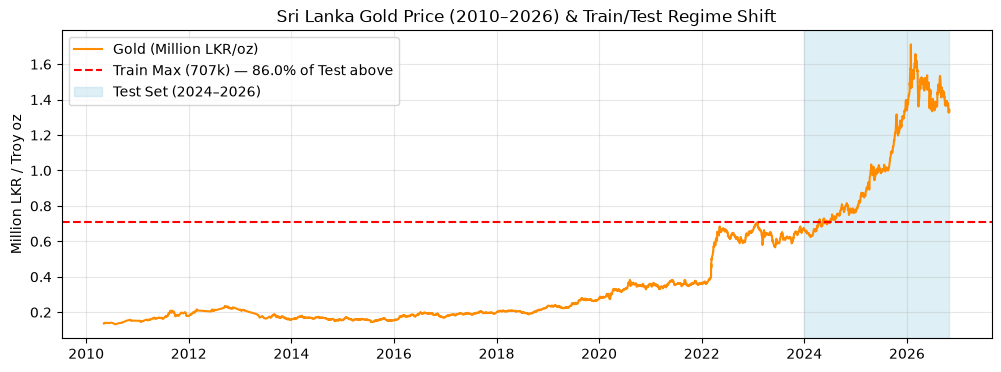

In [21]:
SPLIT_DATE = "2024-01-01"
train_max_gold = df_merged.loc[df_merged["Date"] < SPLIT_DATE, "Gold_LKR"].max()
pct_above = (df_merged.loc[df_merged["Date"] >= SPLIT_DATE, "Gold_LKR"] > train_max_gold).mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df_merged["Date"], df_merged["Gold_LKR"] / 1e6, color="darkorange", label="Gold (Million LKR/oz)")
ax.axhline(train_max_gold / 1e6, color="red", linestyle="--", label=f"Train Max ({train_max_gold/1e3:,.0f}k) — {pct_above:.1f}% of Test above")
ax.axvspan(pd.Timestamp(SPLIT_DATE), df_merged["Date"].max(), color="lightblue", alpha=0.4, label="Test Set (2024–2026)")
ax.set_title("Sri Lanka Gold Price (2010–2026) & Train/Test Regime Shift")
ax.set_ylabel("Million LKR / Troy oz")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

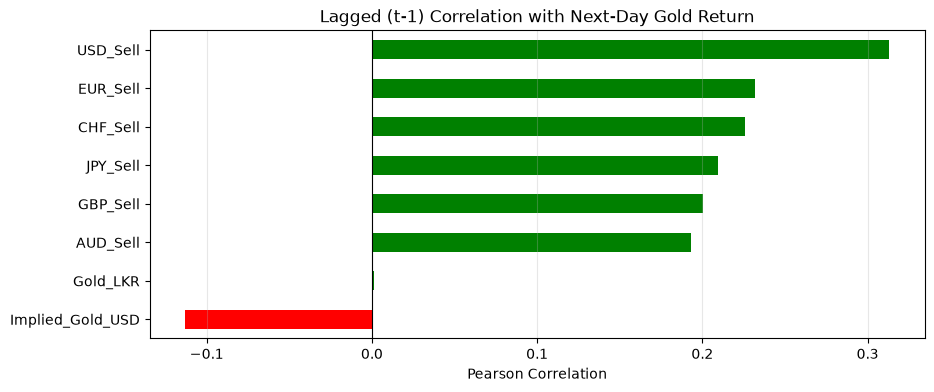

In [22]:
gold_ret = df_merged["Gold_LKR"].pct_change()
cols = ["USD_Sell", "EUR_Sell", "CHF_Sell", "GBP_Sell", "JPY_Sell", "AUD_Sell", "Implied_Gold_USD", "Gold_LKR"]
corrs = pd.Series({c: df_merged[c].pct_change().shift(1).corr(gold_ret) for c in cols}).sort_values()

corrs.plot(kind="barh", figsize=(10, 4), color=["green" if v > 0 else "red" for v in corrs], title="Lagged (t-1) Correlation with Next-Day Gold Return")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson Correlation")
plt.grid(axis="x", alpha=0.3)
plt.show()

### What This Correlation Chart Tells Us
* **Green bars** - Strong positive FX lead - Yesterday's commercial-bank FX returns—led by `USD_Sell` ($r \approx +0.32$), followed other currencies positively correlate with today's Sri Lanka Gold return.
* **Gold_LKR** - Near-zero Gold autocorrelation - Yesterday's Gold return alone barely predicts today's Gold return, hence we can understand that historical gold pricing cannot predict tomorrow price properly, and that's it's not a good metric alone.


* **Red bars** - Implied_Gold_USD is showing a negative corelation as `Implied_Gold_USD = Gold_LKR / USD_Mid` and since USD_Mid has moved before Gold_LKR has adjusted, Implied_Gold_USD falls behind, which actually proves the lag. This would actually create a  mean-reversion signal for our tree models.


### Lagged (t-1) Feature Engineering —
This approach was taken to make sure no data leakage would happen

In [23]:
def build_lagged_features(df_m):
    df_f = df_m[["Date", "Gold_LKR", "Gold_Pawan_LKR"]].copy()

    # Target variables (day t)
    df_f["Target_Gold_LKR"] = df_m["Gold_LKR"]
    df_f["Prev_Gold_LKR"] = df_m["Gold_LKR"].shift(1)
    df_f["Target_Gold_Ret"] = df_m["Gold_LKR"].pct_change(fill_method=None)  # (Gold_t - Gold_{t-1}) / Gold_{t-1}

    # Strictly lagged (t-1) multi-horizon returns across Gold & 8 CBSL currencies
    rate_cols = ["Gold_LKR", "Implied_Gold_USD", "USD_Sell", "EUR_Sell", "GBP_Sell", "CHF_Sell", "AUD_Sell", "CAD_Sell", "SGD_Sell", "JPY_Sell"]
    for col in rate_cols:
        for w in [1, 3, 5]:
            df_f[f"{col}_ret{w}_lag1"] = df_m[col].pct_change(w, fill_method=None).shift(1)

    # Additional autoregressive lags for key drivers (USD & Gold)
    for lag in [2, 3, 5]:
        df_f[f"USD_ret1_lag{lag}"] = df_m["USD_Sell"].pct_change(fill_method=None).shift(lag)
        df_f[f"Gold_ret1_lag{lag}"] = df_m["Gold_LKR"].pct_change(fill_method=None).shift(lag)

    # Rolling volatility & trend momentum (strictly up to t-1)
    g_ret = df_m["Gold_LKR"].pct_change(fill_method=None)
    u_ret = df_m["USD_Sell"].pct_change(fill_method=None)
    for w in [5, 14, 30]:
        df_f[f"Gold_vol{w}_lag1"] = g_ret.rolling(w).std().shift(1)
        df_f[f"USD_vol{w}_lag1"] = u_ret.rolling(w).std().shift(1)
        df_f[f"Gold_ma_ratio{w}_lag1"] = (df_m["Gold_LKR"] / df_m["Gold_LKR"].rolling(w).mean() - 1.0).shift(1)

    # Sri Lankan banking liquidity stress proxy with lagged USD Bid-Ask spread %
    df_f["USD_Spread_Pct_lag1"] = df_m["USD_Spread_Pct"].shift(1)
    df_f["USD_Spread_Pct_chg5_lag1"] = df_m["USD_Spread_Pct"].diff(5).shift(1)

    # Calendar and cyclical features
    df_f["DayOfWeek"] = df_f["Date"].dt.day_of_week
    df_f["Month_Sin"] = np.sin(2 * np.pi * df_f["Date"].dt.month / 12.0)
    df_f["Month_Cos"] = np.cos(2 * np.pi * df_f["Date"].dt.month / 12.0)
    return df_f

### Drop initial rolling-window NaNs & export

In [24]:
df_feat = build_lagged_features(df_merged).dropna().reset_index(drop=True)

# Correct feature column names, made by filtering the features not needed
FEATURE_COLS = [c for c in df_feat.columns if c not in ["Date", "Gold_LKR", "Gold_Pawan_LKR", "Target_Gold_LKR", "Prev_Gold_LKR", "Target_Gold_Ret"]]



Export to a CSV, and Display in the ipynb

In [25]:
df_feat.to_csv("cbsl_gold_fx_features.csv", index=False, date_format="%Y-%m-%d")
print(f"Engineered {len(FEATURE_COLS)} strictly lagged features across {len(df_feat)} trading days.")
print(f"Saved -> cbsl_gold_fx_features.csv | Remaining NaNs: {df_feat.isnull().sum().sum()}")

display(df_feat[["Date", "Target_Gold_LKR", "Target_Gold_Ret", "USD_Sell_ret1_lag1", "Gold_vol14_lag1", "USD_Spread_Pct_lag1"]].head())

Engineered 50 strictly lagged features across 3487 trading days.
Saved -> cbsl_gold_fx_features.csv | Remaining NaNs: 0


,Date,Target_Gold_LKR,Target_Gold_Ret,USD_Sell_ret1_lag1,Gold_vol14_lag1,USD_Spread_Pct_lag1
0,2011-01-21,149467.8598,-0.014548,-0.003654,0.016800,0.015473
1,2011-01-24,149841.0115,0.002497,0.000805,0.017645,0.015371
2,2011-01-25,147864.0389,-0.013194,0.000447,0.017400,0.016079
3,2011-01-26,148041.4667,0.001200,-0.001519,0.017907,0.016819
4,2011-01-27,149250.2592,0.008165,0.000179,0.017691,0.015206



## Chronological Train/Test Split & The Tree-Extrapolation Pitfall Demo

Before training our full ensemble suite, we enforce two strict time-series rules:

1. **Strict Chronological Split:** Train on `2011-01-21` to `2023-12-29` (`2,802` trading days) and evaluate strictly out-of-sample on `2024-01-01` to `2026-10-30` (`685` trading days), Strictly avoided Random Sampling as that would lead to data leakage.

2. **Diagnosing Tree Non-Extrapolation:** Decision trees predict weighted averages of training leaf values, meaning they **cannot extrapolate beyond the maximum price observed during training** (`~707k LKR/oz`).

Because **86% of 2024–2026 Sri Lankan Gold prices** rise above `707k` (reaching `1.71M LKR/oz`), we first run a naive **Raw-Price Random Forest** to demonstrate this high-bias failure visually—motivating why our production models predict **stationary daily returns** (reconstructed via $\hat{P}_t = P_{t-1}(1 + \hat{r}_t)$) or **ARIMA residuals (`RF + ARIMA`)**.

### Import necessary libraries

In [26]:
import os
import pickle
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA

In [27]:
# Load dataset
df_model = pd.read_csv("cbsl_gold_fx_features.csv", parse_dates=["Date"])
META_COLS = ["Date", "Gold_LKR", "Gold_Pawan_LKR", "Target_Gold_LKR", "Prev_Gold_LKR", "Target_Gold_Ret"] # Not in the models
FEATURE_COLS = [c for c in df_model.columns if c not in META_COLS] # Used in the Model
TROY_OZ_TO_PAWAN = 8.0 / 31.1034768

SPLIT_DATE = "2024-01-01"
train_df = df_model[df_model["Date"] < SPLIT_DATE].copy().reset_index(drop=True)
test_df  = df_model[df_model["Date"] >= SPLIT_DATE].copy().reset_index(drop=True)

In [28]:
X_train, y_train_ret = train_df[FEATURE_COLS], train_df["Target_Gold_Ret"]
X_test,  y_test_ret  = test_df[FEATURE_COLS],  test_df["Target_Gold_Ret"]
y_test_lvl = test_df["Target_Gold_LKR"].values
prev_test_lvl = test_df["Prev_Gold_LKR"].values

print(f"Train set: {len(train_df):,} trading days ({train_df['Date'].min().date()} -> {train_df['Date'].max().date()})")
print(f"Test set : {len(test_df):,} trading days ({test_df['Date'].min().date()} -> {test_df['Date'].max().date()})")
print(f"Features : {len(FEATURE_COLS)} strictly lagged (t-1) predictors")

Train set: 2,802 trading days (2011-01-21 -> 2023-12-29)
Test set : 685 trading days (2024-01-01 -> 2026-10-30)
Features : 50 strictly lagged (t-1) predictors


In [29]:
# Evaluation helper function
results_list = []
test_preds_lvl = {"Date": test_df["Date"].values, "Actual_Gold_LKR": y_test_lvl, "Prev_Gold_LKR": prev_test_lvl}

def evaluate_model(name, category, pred_lvl, pred_ret=None):
    pred_lvl = np.asarray(pred_lvl, dtype=float)
    if pred_ret is None:
        pred_ret = (pred_lvl - prev_test_lvl) / prev_test_lvl
    else:
        pred_ret = np.asarray(pred_ret, dtype=float)

    rmse = np.sqrt(mean_squared_error(y_test_lvl, pred_lvl))
    mae  = mean_absolute_error(y_test_lvl, pred_lvl)
    mape = np.mean(np.abs((y_test_lvl - pred_lvl) / y_test_lvl)) * 100.0
    r2_l = r2_score(y_test_lvl, pred_lvl)
    r2_r = r2_score(y_test_ret.values, pred_ret)
    nz = y_test_ret.values != 0
    dir_acc = np.nan if np.allclose(pred_ret, 0) else (np.sign(pred_ret[nz]) == np.sign(y_test_ret.values[nz])).mean() * 100.0

    test_preds_lvl[name] = pred_lvl
    row = {
        "Model": name,
        "Paradigm": category,
        "RMSE (LKR/oz)": rmse,
        "RMSE (LKR/Pawan)": rmse * TROY_OZ_TO_PAWAN,
        "MAE (LKR/oz)": mae,
        "MAPE (%)": mape,
        "R2 (Level)": r2_l,
        "R2 (Return)": r2_r,
        "Dir. Accuracy (%)": dir_acc,
    }
    results_list.append(row)
    return row



In [30]:
# Baseline: tomorrow's price = today's price
evaluate_model("Naive Persistence (y[t-1])", "Baseline", prev_test_lvl, np.zeros_like(prev_test_lvl))



{'Model': 'Naive Persistence (y[t-1])',
 'Paradigm': 'Baseline',
 'RMSE (LKR/oz)': np.float64(17752.482373370916),
 'RMSE (LKR/Pawan)': np.float64(4566.044494002269),
 'MAE (LKR/oz)': 11018.459298394155,
 'MAPE (%)': np.float64(0.9688454961721958),
 'R2 (Level)': 0.9968110728891952,
 'R2 (Return)': -0.006381168792512604,
 'Dir. Accuracy (%)': nan}

In [31]:
# Pitfall Demo (Diagnostic Only — Excluded from Leaderboard): Raw-Price Random Forest
rf_raw_price = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
rf_raw_price.fit(train_df[["Prev_Gold_LKR"] + FEATURE_COLS], train_df["Target_Gold_LKR"])
pred_rf_raw = rf_raw_price.predict(test_df[["Prev_Gold_LKR"] + FEATURE_COLS])
test_preds_lvl["RF (Raw Price — Ceiling Demo)"] = pred_rf_raw
raw_rmse = np.sqrt(mean_squared_error(y_test_lvl, pred_rf_raw))
raw_mape = np.mean(np.abs((y_test_lvl - pred_rf_raw) / y_test_lvl)) * 100.0
raw_r2 = r2_score(y_test_lvl, pred_rf_raw)

print(f"\n[Pitfall Demo] Raw-Price RF Test RMSE: {raw_rmse:,.2f} LKR | MAPE: {raw_mape:.2f}% | R2: {raw_r2:.4f}")
print(f"Max predicted by Raw-Price RF: {pred_rf_raw.max():,.0f} LKR vs. Actual Test Max: {y_test_lvl.max():,.0f} LKR")


[Pitfall Demo] Raw-Price RF Test RMSE: 489,491.77 LKR | MAPE: 30.11% | R2: -1.4245
Max predicted by Raw-Price RF: 682,548 LKR vs. Actual Test Max: 1,711,694 LKR



## Step 4: Ensemble Suite — Bagging, Boosting, Tuning (`TimeSeriesSplit`) & Stacking

Now we train and compare every ensemble paradigm covered in the lecture on the stationary daily return target (`Target_Gold_Ret`) and reconstruct next-day Gold prices via $\hat{P}_t = P_{t-1} (1 + \hat{r}_t)$:
1. **Bagging:** `RandomForestRegressor(oob_score=True)` — parallel decorrelated trees (`max_features="sqrt"`) reducing variance, plus built-in **Out-of-Bag (OOB)** validation.
2. **Boosting (Sequential Bias Reduction):**
   * **`XGBoost`** (`tree_method="hist"`, second-order gradient + Hessian optimization with L1/L2 penalties) — **tuned via `GridSearchCV` + `TimeSeriesSplit(n_splits=5)`**.
   * **`LightGBM`** (histogram leaf-wise boosting).
   * **`CatBoost`** (symmetric/oblivious trees + ordered boosting, highly resistant to financial market noise).
3. **Stacking (Heterogeneous Meta-Learning):** `StackingRegressor` combining `Random Forest`, `Tuned XGBoost`, `LightGBM`, `CatBoost`, and a scaled linear `Ridge` model via a `RidgeCV` meta-learner to capture both bias and variance reduction.

In [32]:
# 1. Bagging: Random Forest with Out-of-Bag (OOB) validation
rf_model = RandomForestRegressor(
    n_estimators=300, max_depth=6, min_samples_leaf=15,
    max_features="sqrt", oob_score=True, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train_ret)
rf_pred_ret = rf_model.predict(X_test)
print(f"[Bagging] Random Forest OOB R2 (Daily Return): {rf_model.oob_score_:.4f}")
evaluate_model("Random Forest (Bagging)", "Bagging", prev_test_lvl * (1 + rf_pred_ret), rf_pred_ret)



[Bagging] Random Forest OOB R2 (Daily Return): 0.0420


{'Model': 'Random Forest (Bagging)',
 'Paradigm': 'Bagging',
 'RMSE (LKR/oz)': np.float64(17538.500677121527),
 'RMSE (LKR/Pawan)': np.float64(4511.007123710755),
 'MAE (LKR/oz)': 10834.46405675468,
 'MAPE (%)': np.float64(0.954368761842873),
 'R2 (Level)': 0.9968874858089384,
 'R2 (Return)': 0.014402682283245594,
 'Dir. Accuracy (%)': np.float64(54.16058394160584)}

### Boosting with XGBoost along with Hyperparameter Tuning
* GridSearchCV tests all 24 hyperparameter combinations using 5 chronological expanding folds
* (TimeSeriesSplit) inside the 2011-2023 training block so tuning never leaks future dates.

In [33]:
tscv = TimeSeriesSplit(n_splits=5)
xgb_param_grid = {
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.03],
    "min_child_weight": [15, 30],
    "reg_lambda": [5.0, 15.0],
}
xgb_search = GridSearchCV(
    XGBRegressor(n_estimators=250, subsample=0.8, colsample_bytree=0.7, reg_alpha=0.1, tree_method="hist", random_state=42, n_jobs=-1),
    param_grid=xgb_param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
xgb_search.fit(X_train, y_train_ret)
xgb_tuned = xgb_search.best_estimator_
xgb_tuned_ret = xgb_tuned.predict(X_test)
res_xgb_tuned = evaluate_model("XGBoost (Tuned)", "Boosting", prev_test_lvl * (1 + xgb_tuned_ret), xgb_tuned_ret)
print(f"[Tuning] Best XGBoost Params: {xgb_search.best_params_}")
print(f"[Tuning] Tuned XGBoost Test RMSE: {res_xgb_tuned['RMSE (LKR/oz)']:,.2f} LKR (CV Return RMSE: {-xgb_search.best_score_:.5f})")


[Tuning] Best XGBoost Params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 15, 'reg_lambda': 5.0}
[Tuning] Tuned XGBoost Test RMSE: 17,540.23 LKR (CV Return RMSE: 0.01039)


### Boosting with LightGBM

In [34]:
lgbm_model = LGBMRegressor(
    n_estimators=300, learning_rate=0.02, max_depth=3, num_leaves=7,
    min_child_samples=30, subsample=0.8, colsample_bytree=0.7,
    reg_alpha=0.1, reg_lambda=5.0, random_state=42, verbose=-1
)
lgbm_model.fit(X_train, y_train_ret)
lgbm_pred_ret = lgbm_model.predict(X_test)
evaluate_model("LightGBM (Boosting)", "Boosting", prev_test_lvl * (1 + lgbm_pred_ret), lgbm_pred_ret)


{'Model': 'LightGBM (Boosting)',
 'Paradigm': 'Boosting',
 'RMSE (LKR/oz)': np.float64(17662.638560324896),
 'RMSE (LKR/Pawan)': np.float64(4542.936128690255),
 'MAE (LKR/oz)': 10915.387320822387,
 'MAPE (%)': np.float64(0.9625001881067747),
 'R2 (Level)': 0.9968432689928628,
 'R2 (Return)': -0.005625445296004061,
 'Dir. Accuracy (%)': np.float64(54.598540145985396)}

### Boosting with CatBoost (Symmetric/Oblivious Trees + Ordered Boosting)

In [35]:
cat_model = CatBoostRegressor(
    iterations=400, learning_rate=0.02, depth=4,
    l2_leaf_reg=10.0, random_seed=42, verbose=0, allow_writing_files=False
)
cat_model.fit(X_train, y_train_ret)
cat_pred_ret = cat_model.predict(X_test)
evaluate_model("CatBoost (Boosting)", "Boosting", prev_test_lvl * (1 + cat_pred_ret), cat_pred_ret)


{'Model': 'CatBoost (Boosting)',
 'Paradigm': 'Boosting',
 'RMSE (LKR/oz)': np.float64(17429.13476782246),
 'RMSE (LKR/Pawan)': np.float64(4482.8775586457805),
 'MAE (LKR/oz)': 10825.636372636383,
 'MAPE (%)': np.float64(0.9539134115271066),
 'R2 (Level)': 0.9969261825727213,
 'R2 (Return)': 0.02410691061039094,
 'Dir. Accuracy (%)': np.float64(54.598540145985396)}

### Stacking: Heterogeneous Base Learners -> Regularized RidgeCV Meta-Learner

In [36]:
stack_model = StackingRegressor(
    estimators=[
        ("rf", RandomForestRegressor(n_estimators=200, max_depth=6, min_samples_leaf=15, max_features="sqrt", random_state=42, n_jobs=-1)),
        ("xgb", XGBRegressor(**xgb_tuned.get_params())),
        ("lgbm", LGBMRegressor(n_estimators=250, learning_rate=0.02, max_depth=3, num_leaves=7, min_child_samples=30, subsample=0.8, colsample_bytree=0.7, reg_lambda=5.0, random_state=42, verbose=-1)),
        ("cat", CatBoostRegressor(iterations=300, learning_rate=0.02, depth=4, l2_leaf_reg=10.0, random_seed=42, verbose=0, allow_writing_files=False)),
        ("ridge", make_pipeline(StandardScaler(), Ridge(alpha=200.0))),
    ],
    final_estimator=RidgeCV(alphas=np.logspace(-1, 3, 25)),
    cv=5,
    n_jobs=-1,
)
stack_model.fit(X_train, y_train_ret)
stack_pred_ret = stack_model.predict(X_test)
evaluate_model("Stacking Ensemble (RidgeCV Meta)", "Stacking", prev_test_lvl * (1 + stack_pred_ret), stack_pred_ret)

meta_weights = dict(zip([name for name, _ in stack_model.estimators], np.round(stack_model.final_estimator_.coef_, 4)))
print(f"[Stacking] Learned Meta-Learner Weights: {meta_weights}")

[Stacking] Learned Meta-Learner Weights: {'rf': np.float64(0.058), 'xgb': np.float64(0.0354), 'lgbm': np.float64(0.046), 'cat': np.float64(0.0379), 'ridge': np.float64(0.2419)}


## Time-Series Hybridization (`RF + ARIMA` & `CatBoost + ARIMA`)

Let's benchmark standalone `ARIMA(1,1,1)` against two two-stage hybrid architectures by comparing **Bagging (`RF`)** vs. **Boosting (`CatBoost`)** as the nonlinear residual learner in the 2nd stage:
* **Stage 1 (`ARIMA(1, 1, 1)` on $\log(\text{Gold\_LKR})$):** Captures the non-stationary linear trend, drift, and short-run autocorrelation—cleanly extrapolating past the `707k` training ceiling all the way to `1.71M LKR`. Parameters are fitted **strictly on the training set** and applied causally 1-step-ahead across the test set via `statsmodels`' Kalman filter (`.apply()`), preventing any look-ahead leakage.
* **Stage 2 (`RandomForestRegressor` & `CatBoostRegressor` on ARIMA Residuals):** Each model learns the nonlinear cross-currency FX residuals $e_t = \log(P_t) - \hat{z}_t^{\text{ARIMA}}$ using our `50` strictly lagged CBSL features. Final forecast: $\hat{P}_t = \exp(\hat{z}_t^{\text{ARIMA}} + \hat{e}_t^{\text{Tree}})$.

### Standalone ARIMA(1, 1, 1) on log(Gold_LKR)

In [37]:
log_gold_all = np.log(df_model["Target_Gold_LKR"].values)
n_train = len(train_df)

arima_spec = ARIMA(log_gold_all[:n_train], order=(1, 1, 1), trend="t")
arima_fit = arima_spec.fit()

# Causal 1-step-ahead Kalman filter predictions with frozen train parameters (zero look-ahead)
arima_applied = arima_fit.apply(log_gold_all)
arima_pred_log_all = arima_applied.fittedvalues
arima_pred_tr_log = arima_pred_log_all[:n_train]
arima_pred_te_log = arima_pred_log_all[n_train:]

res_arima = evaluate_model("ARIMA(1,1,1) Standalone", "Time-Series Baseline", np.exp(arima_pred_te_log))

# Shared Stage-2 target: ARIMA training residuals (skip t=0 initialization step)
arima_resid_tr = log_gold_all[1:n_train] - arima_pred_tr_log[1:]


### Hybrid RF + ARIMA (Bagging Stage-2): RF learns nonlinear FX/macro residuals left behind by ARIMA

In [38]:
rf_arima_resid_model = RandomForestRegressor(
    n_estimators=300, max_depth=6, min_samples_leaf=15,
    max_features="sqrt", oob_score=True, random_state=42, n_jobs=-1
)
rf_arima_resid_model.fit(X_train.iloc[1:], arima_resid_tr)
rf_arima_resid_te = rf_arima_resid_model.predict(X_test)
pred_hybrid_rf_arima = np.exp(arima_pred_te_log + rf_arima_resid_te)

res_rf_arima = evaluate_model("Hybrid: RF + ARIMA", "Hybrid (Time-Series)", pred_hybrid_rf_arima)
print(f"[Hybrid RF+ARIMA]       Standalone ARIMA RMSE: {res_arima['RMSE (LKR/oz)']:,.2f} -> {res_rf_arima['RMSE (LKR/oz)']:,.2f} LKR (Delta: {res_rf_arima['RMSE (LKR/oz)'] - res_arima['RMSE (LKR/oz)']:+,.2f} LKR)")


[Hybrid RF+ARIMA]       Standalone ARIMA RMSE: 17,767.52 -> 17,566.57 LKR (Delta: -200.95 LKR)


### Hybrid CatBoost + ARIMA (Boosting Stage-2): Symmetric-tree CatBoost learns nonlinear FX residuals

In [39]:
cat_arima_resid_model = CatBoostRegressor(
    iterations=400, learning_rate=0.02, depth=4,
    l2_leaf_reg=10.0, random_seed=42, verbose=0, allow_writing_files=False
)
cat_arima_resid_model.fit(X_train.iloc[1:], arima_resid_tr)
cat_arima_resid_te = cat_arima_resid_model.predict(X_test)
pred_hybrid_cat_arima = np.exp(arima_pred_te_log + cat_arima_resid_te)

res_cat_arima = evaluate_model("Hybrid: CatBoost + ARIMA", "Hybrid (Time-Series)", pred_hybrid_cat_arima)
print(f"[Hybrid CatBoost+ARIMA] Standalone ARIMA RMSE: {res_arima['RMSE (LKR/oz)']:,.2f} -> {res_cat_arima['RMSE (LKR/oz)']:,.2f} LKR (Delta: {res_cat_arima['RMSE (LKR/oz)'] - res_arima['RMSE (LKR/oz)']:+,.2f} LKR)")

[Hybrid CatBoost+ARIMA] Standalone ARIMA RMSE: 17,767.52 -> 17,572.82 LKR (Delta: -194.70 LKR)


### Comparison of the 3 ARIMA-Based Models

**Key Observations:**
* **Why Standalone ARIMA lags:** It cleanly extrapolates the 2024–2026 trend past the `707k` training ceiling, but only sees past Gold prices and ignores our 50 lagged CBSL FX features—so it slightly trails Naive Persistence (`17,752.48 LKR/oz`).
* **Why Both Hybrids Wins over the Standalone:** Layering a Stage-2 tree ensemble onto ARIMA's residuals injects the missing cross-currency FX signal, cutting **`~195–201 LKR/oz`** off standalone ARIMA and beating Naive Persistence.
* **Why `RF + ARIMA` slightly beats `CatBoost + ARIMA`:** Once ARIMA removes the linear trend and short-run autocorrelation, the remaining residuals have a lower signal-to-noise ratio—where Bagging's variance averaging (`Random Forest`) resists overfitting noise slightly better than sequential boosting (`CatBoost`).

## Model Leaderboard, Diagnostic Visualizations & Feature Importance!!!

Assembled the  9-model chronological out-of-sample leaderboard (`2024–2026`, `685` trading days) covering our **7 core ensemble & hybrid models** (Bagging, 3 Boosters, Stacking, `RF + ARIMA`, `CatBoost + ARIMA`) and **2 baselines** (`Naive Persistence` & `ARIMA(1,1,1)`), followed by three diagnostic visual panels:
1. **Actual vs. Predicted Trajectory:** Contrasting Raw-Price RF's `707k` ceiling collapse against our top return/hybrid models tracking cleanly to `1.71M LKR/oz` (plus a zoomed view of the most recent 60 trading days in **LKR per Pawan / 8g**).
2. **RMSE & Directional Accuracy Comparison:** Visually highlighting how Bagging, Boosting, Stacking, and ARIMA Hybrids outperform Naive Persistence and standalone ARIMA.
3. **Cross-Model Feature Importance:** Comparing the normalized top drivers across `Random Forest`, `Tuned XGBoost`, `LightGBM`, and `CatBoost`.


Let's check on the Leaderboard Table (sorted by Test RMSE)

In [40]:
leaderboard_df = pd.DataFrame(results_list).sort_values("RMSE (LKR/oz)").reset_index(drop=True)
leaderboard_df.index = leaderboard_df.index + 1
leaderboard_df.index.name = "Rank"

try:
    display(
        leaderboard_df.style.format({
            "RMSE (LKR/oz)": "{:,.2f}",
            "RMSE (LKR/Pawan)": "{:,.2f}",
            "MAE (LKR/oz)": "{:,.2f}",
            "MAPE (%)": "{:.4f}%",
            "R2 (Level)": "{:.4f}",
            "R2 (Return)": "{:.4f}",
            "Dir. Accuracy (%)": lambda v: "—" if pd.isna(v) else f"{v:.2f}%",
        }).highlight_min(subset=["RMSE (LKR/oz)", "MAE (LKR/oz)", "MAPE (%)"], color="#dcfce7")
          .highlight_max(subset=["R2 (Return)", "Dir. Accuracy (%)"], color="#dbeafe")
    )
except (ImportError, AttributeError):
    display(leaderboard_df.round({
        "RMSE (LKR/oz)": 2,
        "RMSE (LKR/Pawan)": 2,
        "MAE (LKR/oz)": 2,
        "MAPE (%)": 4,
        "R2 (Level)": 4,
        "R2 (Return)": 4,
        "Dir. Accuracy (%)": 2,
    }))

,Model,Paradigm,RMSE (LKR/oz),RMSE (LKR/Pawan),MAE (LKR/oz),MAPE (%),R2 (Level),R2 (Return),Dir. Accuracy (%)
Rank,,,,,,,,,
1,CatBoost (Boosting),Boosting,"17,429.13","4,482.88","10,825.64",0.9539%,0.9969,0.0241,54.60%
2,Random Forest (Bagging),Bagging,"17,538.50","4,511.01","10,834.46",0.9544%,0.9969,0.0144,54.16%
3,XGBoost (Tuned),Boosting,"17,540.23","4,511.45","10,847.43",0.9554%,0.9969,0.0128,54.01%
4,Hybrid: RF + ARIMA,Hybrid (Time-Series),"17,566.57","4,518.23","10,844.87",0.9556%,0.9969,0.0102,54.89%
5,Stacking Ensemble (RidgeCV Meta),Stacking,"17,569.27","4,518.92","10,856.14",0.9558%,0.9969,0.0130,57.66%
6,Hybrid: CatBoost + ARIMA,Hybrid (Time-Series),"17,572.82","4,519.83","10,863.21",0.9565%,0.9969,0.0096,54.74%
7,LightGBM (Boosting),Boosting,"17,662.64","4,542.94","10,915.39",0.9625%,0.9968,-0.0056,54.60%
8,Naive Persistence (y[t-1]),Baseline,"17,752.48","4,566.04","11,018.46",0.9688%,0.9968,-0.0064,—
9,"ARIMA(1,1,1) Standalone",Time-Series Baseline,"17,767.52","4,569.91","10,978.46",0.9657%,0.9968,-0.0051,54.45%


### Actual vs. Predicted Gold Price (`2024–2026` Out-of-Sample Backtest)
This chart contrasts our **Raw-Price Random Forest** diagnostic (red flatline stuck near `~683k LKR/oz` because trees cannot extrapolate above the `707k` training maximum) against our stationary return-reconstructed **`CatBoost`** and **`Hybrid: RF + ARIMA`** models, which track the surge to `1.71M LKR/oz` cleanly.

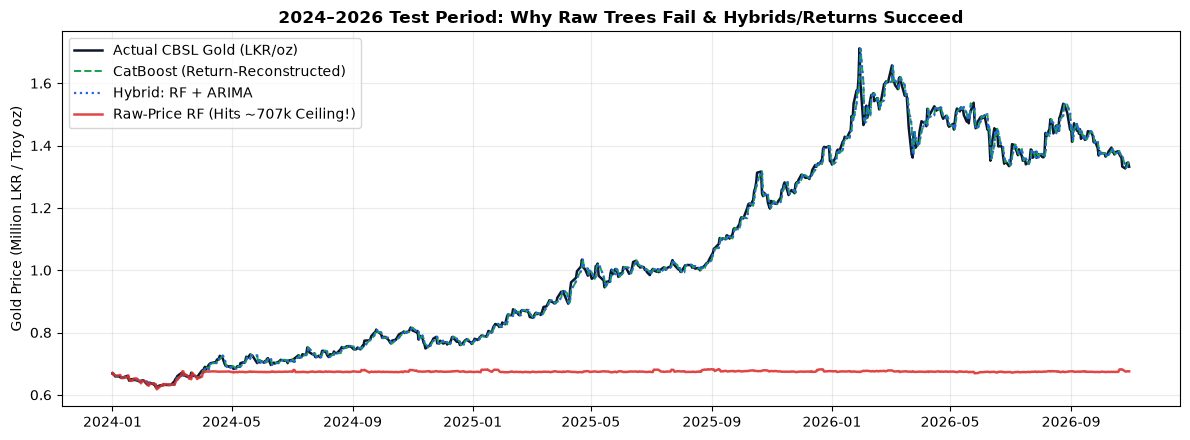

In [41]:
pred_df = pd.DataFrame(test_preds_lvl)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(pred_df["Date"], pred_df["Actual_Gold_LKR"] / 1e6, color="#0f172a", linewidth=1.8, label="Actual CBSL Gold (LKR/oz)")
ax.plot(pred_df["Date"], pred_df["CatBoost (Boosting)"] / 1e6, color="#16a34a", linestyle="--", linewidth=1.4, label="CatBoost (Return-Reconstructed)")
ax.plot(pred_df["Date"], pred_df["Hybrid: RF + ARIMA"] / 1e6, color="#2563eb", linestyle=":", linewidth=1.6, label="Hybrid: RF + ARIMA")
ax.plot(pred_df["Date"], pred_df["RF (Raw Price — Ceiling Demo)"] / 1e6, color="#dc2626", linewidth=1.8, alpha=0.85, label="Raw-Price RF (Hits ~707k Ceiling!)")
ax.set_title("2024–2026 Test Period: Why Raw Trees Fail & Hybrids/Returns Succeed", fontsize=12, fontweight="bold")
ax.set_ylabel("Gold Price (Million LKR / Troy oz)")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Zoomed Last 60 Trading Days (Sri Lankan Local Unit: LKR '000 per 24K Pawan / 8g)
Zooming into the final 60 trading days in **24K Pawan (8g)**—the standard Sri Lankan retail jewellary unit—shows how tightly our top models (`CatBoost`, `Hybrid: RF + ARIMA`, and `Stacking Ensemble`) track day-to-day market fluctuations up through `2026-10-30`.

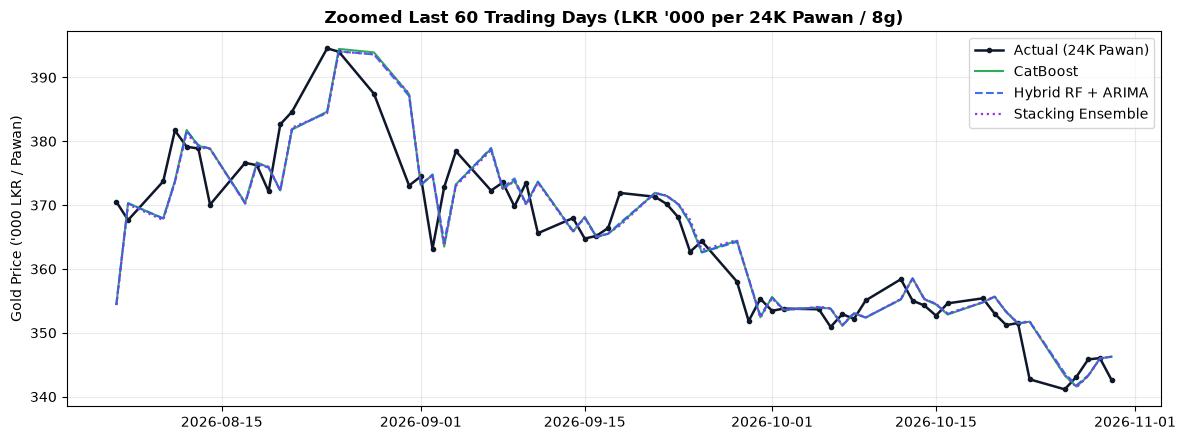

In [42]:
recent = pred_df.tail(60)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(recent["Date"], recent["Actual_Gold_LKR"] * TROY_OZ_TO_PAWAN / 1e3, color="#0f172a", marker="o", markersize=3, linewidth=1.8, label="Actual (24K Pawan)")
ax.plot(recent["Date"], recent["CatBoost (Boosting)"] * TROY_OZ_TO_PAWAN / 1e3, color="#16a34a", linewidth=1.5, alpha=0.9, label="CatBoost")
ax.plot(recent["Date"], recent["Hybrid: RF + ARIMA"] * TROY_OZ_TO_PAWAN / 1e3, color="#2563eb", linestyle="--", linewidth=1.5, alpha=0.9, label="Hybrid RF + ARIMA")
ax.plot(recent["Date"], recent["Stacking Ensemble (RidgeCV Meta)"] * TROY_OZ_TO_PAWAN / 1e3, color="#9333ea", linestyle=":", linewidth=1.6, label="Stacking Ensemble")
ax.set_title("Zoomed Last 60 Trading Days (LKR '000 per 24K Pawan / 8g)", fontsize=12, fontweight="bold")
ax.set_ylabel("Gold Price ('000 LKR / Pawan)")
ax.legend(loc="best")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Leaderboard Bar Charts (9-model leaderboard)

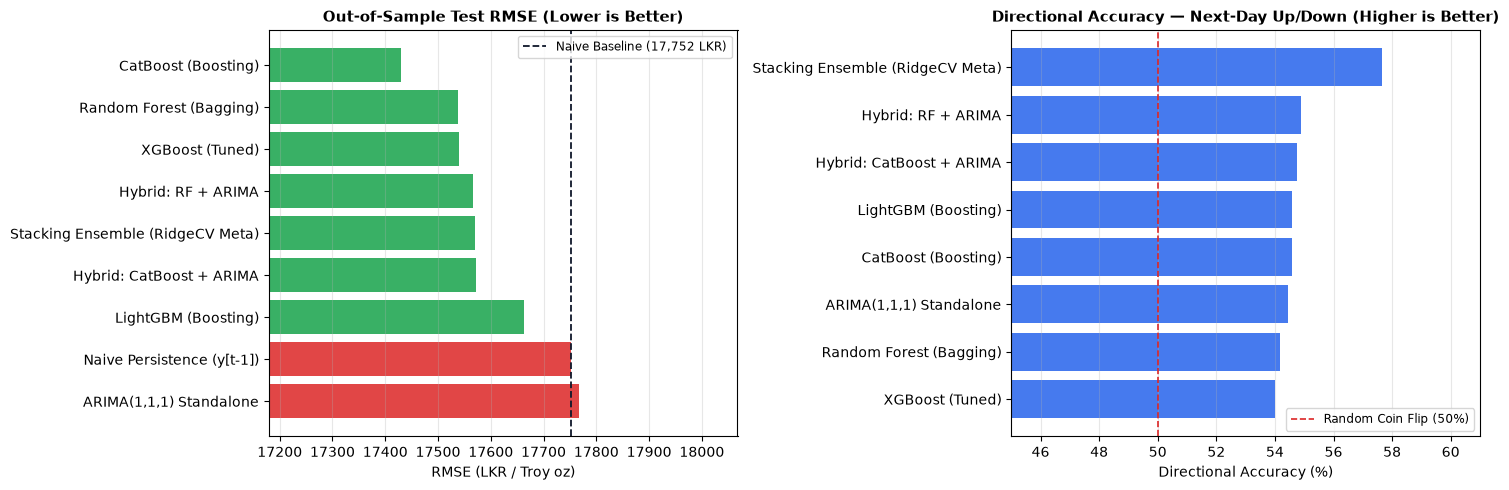

In [43]:
plot_lb = leaderboard_df.copy()
naive_rmse_val = plot_lb.loc[plot_lb["Model"] == "Naive Persistence (y[t-1])", "RMSE (LKR/oz)"].values[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
palette_rmse = ["#16a34a" if v < naive_rmse_val else "#dc2626" for v in plot_lb["RMSE (LKR/oz)"]]
ax1.barh(plot_lb["Model"][::-1], plot_lb["RMSE (LKR/oz)"][::-1], color=palette_rmse[::-1], alpha=0.85)
ax1.axvline(naive_rmse_val, color="#0f172a", linestyle="--", linewidth=1.3, label=f"Naive Baseline ({naive_rmse_val:,.0f} LKR)")
ax1.set_xlim(plot_lb["RMSE (LKR/oz)"].min() - 250, plot_lb["RMSE (LKR/oz)"].max() + 300)
ax1.set_title("Out-of-Sample Test RMSE (Lower is Better)", fontsize=11, fontweight="bold")
ax1.set_xlabel("RMSE (LKR / Troy oz)")
ax1.legend(fontsize=8.5)
ax1.grid(axis="x", alpha=0.3)

dir_df = plot_lb[plot_lb["Model"] != "Naive Persistence (y[t-1])"].sort_values("Dir. Accuracy (%)", ascending=True)
ax2.barh(dir_df["Model"], dir_df["Dir. Accuracy (%)"], color="#2563eb", alpha=0.85)
ax2.axvline(50.0, color="#dc2626", linestyle="--", linewidth=1.2, label="Random Coin Flip (50%)")
ax2.set_xlim(45, 61)
ax2.set_title("Directional Accuracy — Next-Day Up/Down (Higher is Better)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Directional Accuracy (%)")
ax2.legend(fontsize=8.5)
ax2.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Cross-Model Feature Importance Comparison (Normalized % across RF, Tuned XGBoost, LightGBM, CatBoost)

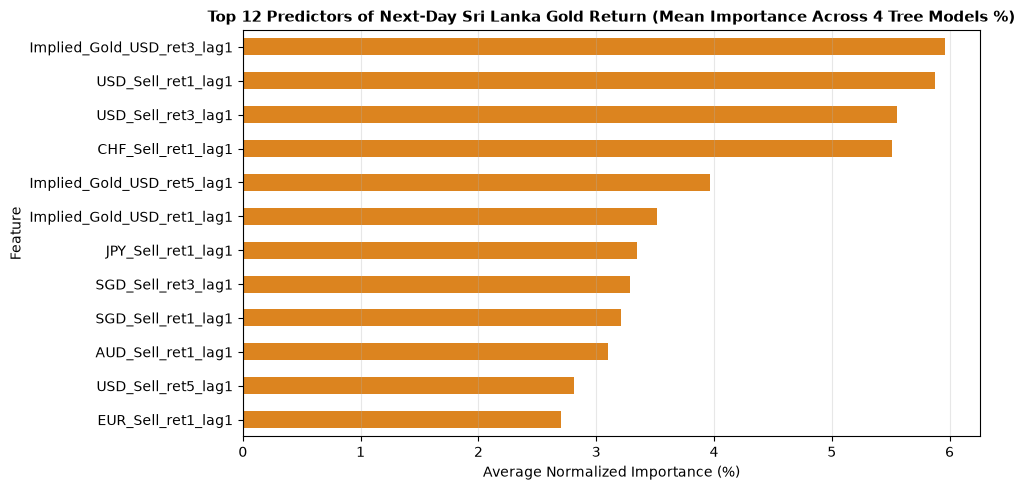

,Feature,Random Forest,XGBoost (Tuned),LightGBM,CatBoost,Mean_Importance
4,Implied_Gold_USD_ret3_lag1,2.57,2.92,4.77,13.59,5.96
6,USD_Sell_ret1_lag1,7.19,2.93,5.87,7.50,5.87
7,USD_Sell_ret3_lag1,7.08,4.68,3.66,6.79,5.55
15,CHF_Sell_ret1_lag1,5.01,2.89,7.11,7.05,5.51
5,Implied_Gold_USD_ret5_lag1,3.47,2.95,4.11,5.32,3.96
3,Implied_Gold_USD_ret1_lag1,1.45,2.55,5.81,4.24,3.51
27,JPY_Sell_ret1_lag1,3.70,2.19,3.13,4.36,3.35
25,SGD_Sell_ret3_lag1,4.07,2.00,4.05,3.04,3.29
24,SGD_Sell_ret1_lag1,5.74,2.18,1.11,3.82,3.21
18,AUD_Sell_ret1_lag1,2.53,2.32,2.68,4.89,3.10


In [44]:
def norm_imp(vals):
    arr = np.asarray(vals, dtype=float)
    return (arr / arr.sum()) * 100.0

feat_imp_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Random Forest": norm_imp(rf_model.feature_importances_),
    "XGBoost (Tuned)": norm_imp(xgb_tuned.feature_importances_),
    "LightGBM": norm_imp(lgbm_model.feature_importances_),
    "CatBoost": norm_imp(cat_model.get_feature_importance()),
})
feat_imp_df["Mean_Importance"] = feat_imp_df[["Random Forest", "XGBoost (Tuned)", "LightGBM", "CatBoost"]].mean(axis=1)
top12_imp = feat_imp_df.sort_values("Mean_Importance", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(10, 5))
top12_imp.set_index("Feature")["Mean_Importance"].iloc[::-1].plot(
    kind="barh", ax=ax, color="#d97706", alpha=0.9
)
ax.set_title("Top 12 Predictors of Next-Day Sri Lanka Gold Return (Mean Importance Across 4 Tree Models %)", fontsize=11, fontweight="bold")
ax.set_xlabel("Average Normalized Importance (%)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(top12_imp[["Feature", "Random Forest", "XGBoost (Tuned)", "LightGBM", "CatBoost", "Mean_Importance"]].round(2))

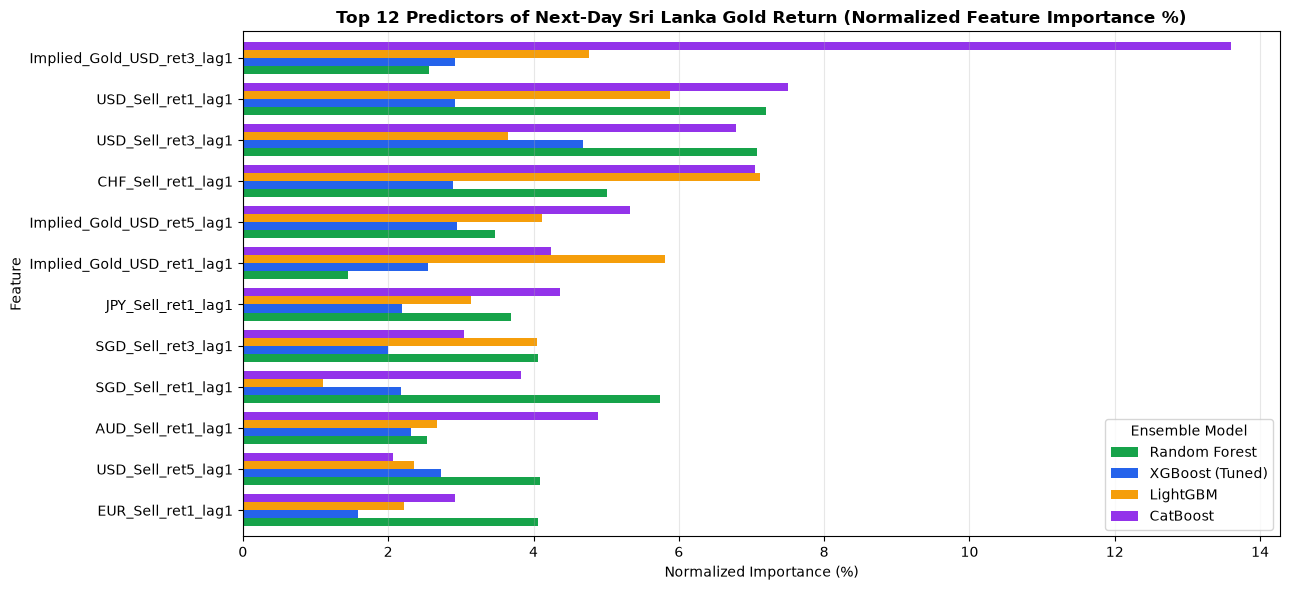

,Feature,Random Forest,XGBoost (Tuned),LightGBM,CatBoost,Mean_Importance
4,Implied_Gold_USD_ret3_lag1,2.57,2.92,4.77,13.59,5.96
6,USD_Sell_ret1_lag1,7.19,2.93,5.87,7.50,5.87
7,USD_Sell_ret3_lag1,7.08,4.68,3.66,6.79,5.55
15,CHF_Sell_ret1_lag1,5.01,2.89,7.11,7.05,5.51
5,Implied_Gold_USD_ret5_lag1,3.47,2.95,4.11,5.32,3.96
3,Implied_Gold_USD_ret1_lag1,1.45,2.55,5.81,4.24,3.51
27,JPY_Sell_ret1_lag1,3.70,2.19,3.13,4.36,3.35
25,SGD_Sell_ret3_lag1,4.07,2.00,4.05,3.04,3.29
24,SGD_Sell_ret1_lag1,5.74,2.18,1.11,3.82,3.21
18,AUD_Sell_ret1_lag1,2.53,2.32,2.68,4.89,3.10


In [45]:
feat_imp_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Random Forest": norm_imp(rf_model.feature_importances_),
    "XGBoost (Tuned)": norm_imp(xgb_tuned.feature_importances_),
    "LightGBM": norm_imp(lgbm_model.feature_importances_),
    "CatBoost": norm_imp(cat_model.get_feature_importance()),
})
feat_imp_df["Mean_Importance"] = feat_imp_df[["Random Forest", "XGBoost (Tuned)", "LightGBM", "CatBoost"]].mean(axis=1)
top12_imp = feat_imp_df.sort_values("Mean_Importance", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(13, 6))
top12_imp.set_index("Feature")[["Random Forest", "XGBoost (Tuned)", "LightGBM", "CatBoost"]].iloc[::-1].plot(
    kind="barh", ax=ax, width=0.78, color=["#16a34a", "#2563eb", "#f59e0b", "#9333ea"]
)
ax.set_title("Top 12 Predictors of Next-Day Sri Lanka Gold Return (Normalized Feature Importance %)", fontsize=12, fontweight="bold")
ax.set_xlabel("Normalized Importance (%)")
ax.grid(axis="x", alpha=0.3)
ax.legend(title="Ensemble Model", loc="lower right")
plt.tight_layout()
plt.show()

display(top12_imp[["Feature", "Random Forest", "XGBoost (Tuned)", "LightGBM", "CatBoost", "Mean_Importance"]].round(2))

## End Section

## Summary & Interpretation of Results

* **Benchmark:** All 7 ensemble and hybrid models beat both **Naive Persistence (`17,752 LKR/oz`)** and standalone **`ARIMA(1,1,1)` (`17,768 LKR/oz`)** by **0.5%–1.8%** across unseen `2024–2026` trading days. Because `R² (Level) ≈ 0.997` is inflated by price persistence, **`R² (Return)` (`+0.0241` max)** and **Directional Accuracy (`54%–58%`)** are the honest skill indicators.


* **Why Target Reformulation Mattered:** Because 86% of 2024–2026 prices sit above the `2011–2023` training maximum (`707k LKR/oz`), raw-price decision trees flatline near `683k` (`489k LKR/oz` RMSE). Predicting **stationary daily returns** (or **ARIMA residuals**) eliminates this ceiling and keeps MAPE under `1%`.


* **Bagging & Boosting:** **`CatBoost`** was the best in the set with the lowest Root mean squared error (`17,429 LKR/oz`)** and `R² (Return)` (`+0.0241`) because symmetric trees + ordered boosting resist noisy daily returns. **`Random Forest`** came in second with a RMSE (`17,539 LKR/oz`, OOB R² `+0.0420`)**, followed by **`XGBoost (Tuned)` (`17,540 LKR/oz`)** tuned via chronological `TimeSeriesSplit(5)`, and **`LightGBM` (`17,663 LKR/oz`)**.


* **Stacking & Hybridization:** **`Stacking Ensemble`** achieved the best Directional Accuracy (`57.66%`) by blending trees with linear `Ridge`. Both time-series hybrids (**`RF + ARIMA`: `-201 LKR/oz`**, **`CatBoost + ARIMA`: `-195 LKR/oz`**) beat standalone ARIMA, with `RF + ARIMA` slightly ahead because Bagging resists overfitting ARIMA's noisier leftover residuals.


* **Top Predictive Drivers & Modality Fit:** Yesterday's `Implied_Gold_USD` 3-day momentum, `USD_Sell`, and `CHF_Sell` returns dominate across all 4 tree models. On structured tabular datasets of this size (`3,487` CBSL rows), regularized tree ensembles and ARIMA hybrids are faster, more accurate, and far more sample-efficient than deep learning (which excels on unstructured image/text data).

### Model Export
Export all to `models/gold_ensemble_bundle.pkl` file, so this can be used in the Streamlit Dashboard.

In [46]:
from pandas.tseries.offsets import BDay

os.makedirs("models", exist_ok=True)
BUNDLE_PATH = os.path.join("models", "gold_ensemble_bundle.pkl")

# 1. Construct TRUE next-trading-day (t+1) lagged feature row from data up through last observed trading day (t)
last_date = pd.Timestamp(df_merged["Date"].iloc[-1])
next_date = last_date + BDay(1)
df_ext = pd.concat([df_merged, pd.DataFrame({"Date": [next_date]})], ignore_index=True)
feat_ext = build_lagged_features(df_ext)
next_X = feat_ext[FEATURE_COLS].iloc[[-1]].copy()
assert not next_X.isnull().any().any(), "next_X contains NaNs!"
pd.testing.assert_frame_equal(
    feat_ext.iloc[:-1].dropna().reset_index(drop=True)[FEATURE_COLS],
    df_feat[FEATURE_COLS],
    check_dtype=False,
)

# Store last known log-gold state 1-step-ahead ARIMA forecast for next_date
arima_last_1step_log = float(np.asarray(arima_applied.forecast(steps=1))[0])
last_gold_lkr = float(df_merged["Gold_LKR"].iloc[-1])
top_features = feat_imp_df.sort_values("Mean_Importance", ascending=False)["Feature"].head(4).tolist()
feature_bounds = {f: (float(X_train[f].quantile(0.01)), float(X_train[f].quantile(0.99))) for f in FEATURE_COLS}

bundle = {
    "feature_cols": FEATURE_COLS,
    "troy_oz_to_pawan": TROY_OZ_TO_PAWAN,
    "split_date": SPLIT_DATE,
    "train_max_gold": float(train_df["Target_Gold_LKR"].max()),
    "rf_oob_r2": float(rf_model.oob_score_),
    "best_xgb_params": xgb_search.best_params_,
    "stack_meta_weights": meta_weights,
    "arima_next_log_forecast": arima_last_1step_log,
    "last_date": last_date,
    "next_date": next_date,
    "last_gold_lkr": last_gold_lkr,
    "next_day_features": next_X,
    "feature_bounds": feature_bounds,
    "top_features": top_features,
    "models": {
        "CatBoost (Boosting)": cat_model,
        "Random Forest (Bagging)": rf_model,
        "XGBoost (Tuned)": xgb_tuned,
        "LightGBM (Boosting)": lgbm_model,
        "Stacking Ensemble (RidgeCV Meta)": stack_model,
        "_rf_arima_resid": rf_arima_resid_model,
        "_cat_arima_resid": cat_arima_resid_model,
    },
    "leaderboard": leaderboard_df.reset_index(),
    "test_predictions": pred_df,
    "feature_importances": feat_imp_df,
}

with open(BUNDLE_PATH, "wb") as f:
    pickle.dump(bundle, f)

size_mb = os.path.getsize(BUNDLE_PATH) / (1024 * 1024)
print(f"Exported model bundle -> {BUNDLE_PATH} ({size_mb:.2f} MB)")

# 2. Verification: Reload pickle & predict the TRUE next trading day (next_date)
with open(BUNDLE_PATH, "rb") as f:
    loaded = pickle.load(f)

X_next = loaded["next_day_features"]
lp = loaded["last_gold_lkr"]
oz_to_pw = loaded["troy_oz_to_pawan"]

print(f"\nLive Next-Day Forecast Verification (Last Observed: {loaded['last_date'].date()} = {lp:,.2f} LKR/oz | Target Date: {loaded['next_date'].date()}):")
next_preds = {}
for m_name in [
    "CatBoost (Boosting)",
    "Random Forest (Bagging)",
    "XGBoost (Tuned)",
    "LightGBM (Boosting)",
    "Stacking Ensemble (RidgeCV Meta)",
]:
    pred_r = float(loaded["models"][m_name].predict(X_next)[0])
    next_preds[m_name] = lp * (1.0 + pred_r)

next_preds["Hybrid: RF + ARIMA"] = float(np.exp(loaded["arima_next_log_forecast"] + loaded["models"]["_rf_arima_resid"].predict(X_next)[0]))
next_preds["Hybrid: CatBoost + ARIMA"] = float(np.exp(loaded["arima_next_log_forecast"] + loaded["models"]["_cat_arima_resid"].predict(X_next)[0]))
next_preds["ARIMA(1,1,1) Standalone"] = float(np.exp(loaded["arima_next_log_forecast"]))

for m_name, next_oz in next_preds.items():
    assert np.isfinite(next_oz), f"{m_name} produced non-finite prediction"
    next_pw = next_oz * oz_to_pw
    chg_pct = (next_oz / lp - 1.0) * 100.0
    print(f"  - {m_name:<33s}: {next_oz:>12,.2f} LKR/oz  |  {next_pw:>10,.2f} LKR/Pawan  ({chg_pct:+.3f}%)")

Exported model bundle -> models/gold_ensemble_bundle.pkl (2.82 MB)

Live Next-Day Forecast Verification (Last Observed: 2026-10-30 = 1,332,002.34 LKR/oz | Target Date: 2026-11-02):
  - CatBoost (Boosting)              : 1,333,046.40 LKR/oz  |  342,867.49 LKR/Pawan  (+0.078%)
  - Random Forest (Bagging)          : 1,333,108.90 LKR/oz  |  342,883.57 LKR/Pawan  (+0.083%)
  - XGBoost (Tuned)                  : 1,333,112.94 LKR/oz  |  342,884.61 LKR/Pawan  (+0.083%)
  - LightGBM (Boosting)              : 1,334,113.73 LKR/oz  |  343,142.02 LKR/Pawan  (+0.159%)
  - Stacking Ensemble (RidgeCV Meta) : 1,333,636.73 LKR/oz  |  343,019.33 LKR/Pawan  (+0.123%)
  - Hybrid: RF + ARIMA               : 1,333,394.68 LKR/oz  |  342,957.08 LKR/Pawan  (+0.105%)
  - Hybrid: CatBoost + ARIMA         : 1,333,293.70 LKR/oz  |  342,931.10 LKR/Pawan  (+0.097%)
  - ARIMA(1,1,1) Standalone          : 1,333,031.80 LKR/oz  |  342,863.74 LKR/Pawan  (+0.077%)


## AI Usage
1. **Google AI Studio** was used in a complete lock down mode, with no internet access to work as on guiding the initial layout by discussing the type of dataset needed for such a study. While I, found the dataset on my own from the central bank website, and decided on merging 2 datasets and creating this new idea.
2. **Antigravity** was used as a coding assistant during this assignment in working with Python, while I, completely reworked on the agents work to make it more focused, and completely reworked in the markdown sections.
3. **Presentation and ReadME file** was done on Canva and was not connected to the agent/ any AI tool.